Head of DataFrame:
          Date   Product Region   Sales  Quantity
0  2024-01-01    Laptop  North  1000.0         1
1  2024-01-02     Mouse  South   150.0         3
2  2024-01-03  Keyboard   East   200.0         2
3  2024-01-04    Laptop   West     NaN         1
4  2024-01-05     Mouse  North   180.0         4

Missing values:
 Date        0
Product     0
Region      0
Sales       1
Quantity    0
dtype: int64

Summary Statistics:
              Sales   Quantity
count    10.000000  10.000000
mean    474.444444   2.000000
std     408.196878   1.054093
min     150.000000   1.000000
25%     185.000000   1.000000
50%     215.000000   2.000000
75%     868.611111   2.750000
max    1100.000000   4.000000

Product Summary:
     Product        Sales  Quantity
0  Keyboard   630.000000         6
1    Laptop  3624.444444         4
2     Mouse   490.000000        10


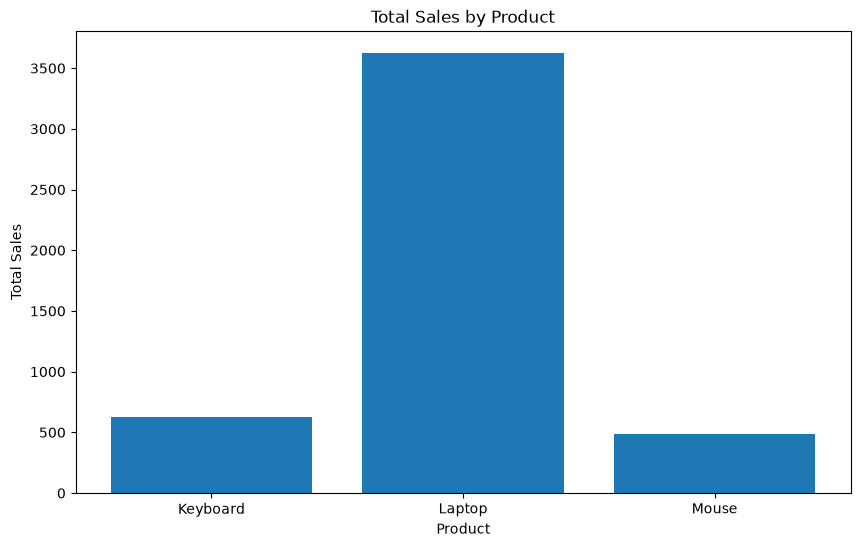

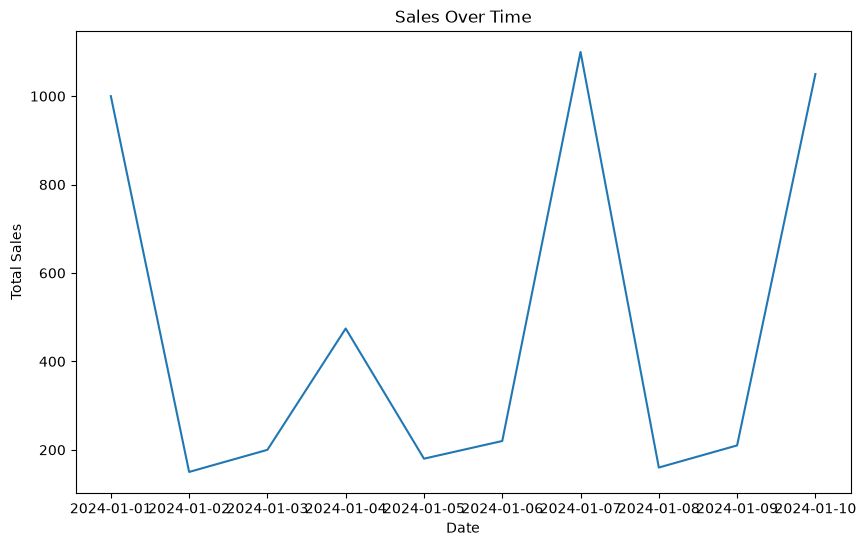


Pivot Table:
 Product  Keyboard       Laptop  Mouse
Region                               
East        200.0  1100.000000    0.0
North       210.0  1000.000000  180.0
South       220.0  1050.000000  150.0
West          0.0   474.444444  160.0

Correlation Matrix:
             Sales  Quantity
Sales     1.00000  -0.76293
Quantity -0.76293   1.00000


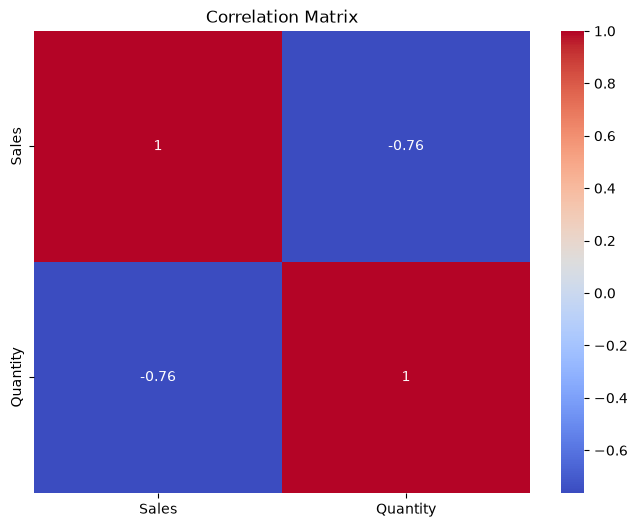

In [4]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the data into a pandas DataFrame
file_path = 'sales_data.csv'  # Modify file path as per your environment
df = pd.read_csv(file_path)

# Display the first few rows
print("Head of DataFrame:\n", df.head())

# Check for missing values
print("\nMissing values:\n", df.isnull().sum())

# Fill or drop missing values
df['Sales'] = df['Sales'].fillna(df['Sales'].mean()) 
df.dropna(subset=['Product', 'Quantity', 'Region'], inplace=True) 

# Summary statistics
print("\nSummary Statistics:\n", df.describe())

# Group by product and calculate total sales and quantity
product_summary = df.groupby('Product').agg({
    'Sales': 'sum',
    'Quantity': 'sum'
}).reset_index() 
print("\nProduct Summary:\n", product_summary)

# 2. Bar plot of total sales by product
plt.figure(figsize=(10, 6))
plt.bar(product_summary['Product'], product_summary['Sales'])
plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.title('Total Sales by Product')
plt.show()

# 3. Line plot of sales over time
df['Date'] = pd.to_datetime(df['Date'])
sales_over_time = df.groupby('Date').agg({'Sales': 'sum'}).reset_index()

plt.figure(figsize=(10, 6))
plt.plot(sales_over_time['Date'], sales_over_time['Sales'])
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.title('Sales Over Time')
plt.show()

# 4. Pivot table to analyze sales by region and product
pivot_table = df.pivot_table(values='Sales', index='Region', columns='Product', aggfunc=np.sum, fill_value=0)
print("\nPivot Table:\n", pivot_table)

# 5. Correlation matrix and Heatmap
correlation_matrix = df.corr(numeric_only=True)
print("\nCorrelation Matrix:\n", correlation_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()